# IRC Plots

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch5/5B-solvent/ch5B-B-irc-plots.ipynb)
:::

As discussed in the [previous notebook](ch5B-A-irc-data.ipynb), we now have **one data file**, `sn2_irc_B3LYP321G.json`, with every point of the gas phase IRC: the distance along the path (the stride), the two C&ndash;Cl bond lengths, and the energy of each structure in gas phase and in water. We can now make some **comparisons**.

Remember that both sets of energies belong to the **same** structures, the ones on the gas phase path. The [first notebook](ch5B-solvent.ipynb) explains why we could not follow the path in water itself with *Psi4*. At the end of this notebook we will compare with the IRC in water that I calculated with *GAMESS*.

This notebook does not run *Psi4*, so the hidden first cell only imports *NumPy*, *pandas* and *Matplotlib* and applies the plot style sheet.

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

# Psi4 output (.out, .log, .molden, cube files, scans) goes into output/, which is not kept in git.
# Small results files that another page reads (.json, .csv) go into data/, which is kept in git.
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

## Importing Stored Data

No need to use the raw data and process the files. We have **stored** that work as a data file and **documented** the process that we used to clean and process the data. Now we can load it in and use it. As before, if the file is not in this folder we download my copy from the book's *GitHub* repository.

In [2]:
# Load the table from the data notebook, or download my copy
url = "https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch5/5B-solvent/data/"
filename = "sn2_irc_B3LYP321G.json"

if (data_dir / filename).exists():
    data = pd.read_json(data_dir / filename)
else:
    data = pd.read_json(url + filename)

display(data.head())

,step,energy gas,stride,C-Cl1,C-Cl2,energy water,solvation,E gas (kJ/mol),E water (kJ/mol)
0,-15,-955.777434,-4.5,2.744540,2.090976,-955.874451,-0.098704,-3.707984,-15.624643
1,-14,-955.777434,-4.2,2.744540,2.090976,-955.874451,-0.098704,-3.706862,-15.624643
2,-13,-955.777435,-3.9,2.744094,2.091167,-955.874436,-0.098684,-3.708671,-15.585548
3,-12,-955.777436,-3.6,2.743381,2.091532,-955.874429,-0.098675,-3.711649,-15.567029
4,-11,-955.777436,-3.3,2.741194,2.092676,-955.874386,-0.098626,-3.712477,-15.454376


| Line | Notes |
| :---- | :---- |
| `pd.read_json(filename)` | Reads a JSON file of records straight into a dataframe, column names and all. It works with a file name or a web address. |

## Plots

First we must **decide** what to plot. How do the energies **compare** in gas phase vs. water as bonds break and form across the transition state? Let us plot the **relative energy** vs. **stride**.

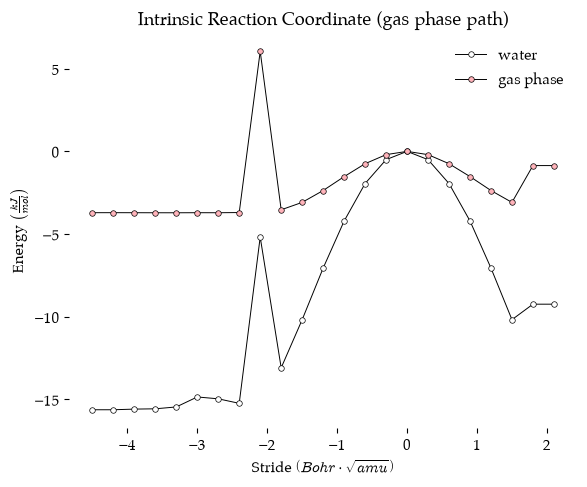

In [3]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,5))

# Energy along the path: water (white) and gas phase (pink)
ax.plot(data["stride"], data["E water (kJ/mol)"], color="black", linewidth=0.7, marker="o",
        markersize=4, markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5,
        label="water")
ax.plot(data["stride"], data["E gas (kJ/mol)"], color="black", linewidth=0.7, marker="o",
        markersize=4, markerfacecolor="#FFB3BA", markeredgecolor="black", markeredgewidth=0.5,
        label="gas phase")

ax.set(title="Intrinsic Reaction Coordinate (gas phase path)",
       ylabel=r"Energy $\left(\frac{kJ}{mol}\right)$",
       xlabel=r"Stride $\left(Bohr \cdot \sqrt{amu}\right)$")
ax.legend()

#fig.savefig("plot1.pdf")
plt.show()

| Line | Notes |
| :---- | :---- |
| `ax.plot(data["stride"], data["E water (kJ/mol)"], ...)` | The water energies: open white circles joined by a thin black line. |
| `markerfacecolor="#FFB3BA"` | The gas phase energies get pastel pink circles. |
| `label="water"` and `ax.legend()` | Each series gets a name, and `legend()` draws the key. |
| `ax.set(title=..., ylabel=..., xlabel=...)` | Sets the title and axis labels at once. Text between `$` signs is typeset as math. |
| `#fig.savefig("plot1.pdf")` | Remove the `#` to save the figure as a PDF file. |

On the smooth part of the path, the gas phase energy falls to 3.08 kJ/mol below the transition state at &plusmn;1.5 and to 3.53 kJ/mol at &minus;1.8; the water energy falls to 10.18 and 13.09 kJ/mol below. Along the flat bottom of the backward run (&minus;2.4 to &minus;4.5) the gas phase energy is 3.71 kJ/mol below the transition state and the water energy about 15.5 kJ/mol below. The zig-zag points from the previous notebooks are 6 kJ/mol **above** the transition state in gas phase at &minus;2.1 (still 5 kJ/mol below it in water), and 0.86 kJ/mol below it at +1.8 and +2.1 (9.2 kJ/mol below in water).

In the gas phase, the **relative energy** between the ground state and the transition state is **much smaller**. This is because the **negatively charged** chloride nucleophile/leaving group is very **high in energy** in a **vacuum** where it cannot share its electrons. In the **solvent** model, the energy is less as chloride can be stabilized by the **electric dipole** of water. In fact the gas phase IRC ends early because the **energy** is actually about to start **going back up** as the nucleophile moves away. In a vacuum, chloride separated widely from the methyl chloride is actually **higher in energy** than the transition state. Our curves agree with the first part: the well is about four times deeper in water. The last part is not something that our path can show, because it never separates the chloride from the methyl chloride. To check it, calculate the energy of a chloride ion and add it to the energy of methyl chloride from the [first notebook](ch5B-solvent.ipynb). That is a good exercise.

## Changing Bond Lengths

The famous More O'Ferrall&ndash;Jencks plot follows one **coordinate** of the reaction with respect to **another**. This reaction has a **nucleophile** that moves in to make a bond and a **leaving group** that departs, breaking a bond. We could plot "making" on one axis and "breaking" on the other.

There are **two** C&ndash;Cl distances on the path: the **incoming** nucleophile and the departing leaving group. The incoming nucleophile starts at a longer distance and **moves** in. The leaving group bond will lengthen. At the transition state, they should be identical (defined by symmetry). Let us plot **one** length against the **other**. Will it be a straight line? Will it be a curve? Our gas and water energies share the same structures, so there is only one path to draw.

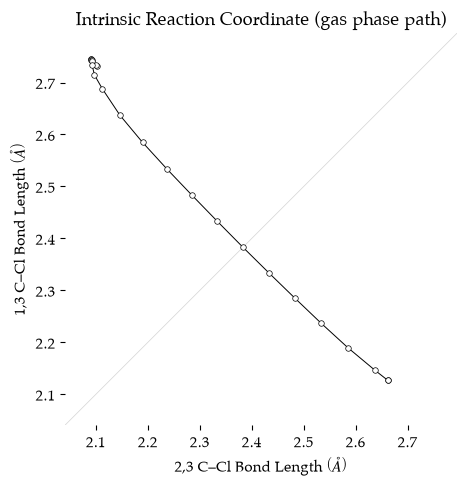

In [4]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,5))

# A gray diagonal where the two C-Cl bonds are equal
low = min(data["C-Cl1"].min(), data["C-Cl2"].min()) - 0.05
high = max(data["C-Cl1"].max(), data["C-Cl2"].max()) + 0.05
ax.plot([low, high], [low, high], color="lightgray", linewidth=0.5, zorder=1)

# One C-Cl distance against the other along the path
ax.plot(data["C-Cl2"], data["C-Cl1"], color="black", linewidth=0.7, marker="o",
        markersize=4, markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5,
        zorder=2)

ax.set(title="Intrinsic Reaction Coordinate (gas phase path)",
       ylabel=r"1,3 C–Cl Bond Length $\left(\AA\right)$",
       xlabel=r"2,3 C–Cl Bond Length $\left(\AA\right)$",
       xlim=[low, high],
       ylim=[low, high])
ax.set_aspect("equal")

#fig.savefig("plot2.pdf")
plt.show()

| Line | Notes |
| :---- | :---- |
| `low = min(...) - 0.05` | The shortest bond length on the path, less a little margin. `high` is the longest plus a margin. Both axes will use the same range. |
| `ax.plot([low, high], [low, high], ...)` | A light gray **diagonal** line where the two bonds are equal. The transition state sits on it. `zorder=1` puts it behind the data. |
| `ax.set_aspect("equal")` | One &Aring;ngstrom is the same length on both axes, so the plot is square and the diagonal is at 45&deg;. |

Near the transition state, both bonds change together, one getting about 0.05 &Aring; longer as the other gets 0.05 &Aring; shorter at each step: a straight line at 45&deg; to the diagonal. Towards the ends the line bends. The forming bond slows down (2.146 &rarr; 2.112 &Aring; between the last two smooth points) while the breaking bond keeps stretching (2.637 &rarr; 2.688 &Aring;). That is the beginning of a hockey stick. Out along the flat bottom of the backward run it bends right over: the breaking bond creeps from 2.688 to 2.745 &Aring; while the forming bond hardly moves (2.112 &rarr; 2.091 &Aring;).

## Comparing with *GAMESS*

How do our energies compare with the IRC **in water** from the *GAMESS* book? The *GAMESS* table is still on *GitHub*, so let us plot the two together. The total energies differ (different versions of B3LYP, and slightly different cavities), but the **relative** energies can be compared. More importantly, the *GAMESS* path was followed **in water**, while ours is the gas phase path with water energies, so this comparison shows what our shortcut misses.

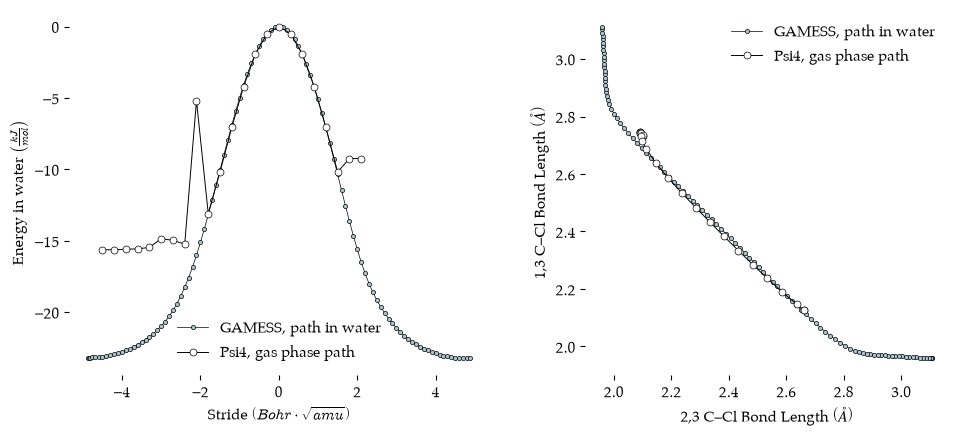

In [5]:
# My GAMESS IRC in water, from the GAMESS book's GitHub repository
gamess_url = "https://raw.githubusercontent.com/blinkletter/UsingGAMESS/main/data/SN2_IRC_Solvent_Data.txt"
gamess = pd.read_csv(gamess_url, index_col=0)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10,4.5))

# Left: energy in water along each path
axs[0].plot(gamess["stride"], gamess["E(kJ/mole)"], color="black", linewidth=0.5, marker="o",
            markersize=3, markerfacecolor="#AEC6CF", markeredgecolor="black", markeredgewidth=0.5,
            label="GAMESS, path in water", zorder=1)
axs[0].plot(data["stride"], data["E water (kJ/mol)"], color="black", linewidth=0.7, marker="o",
            markersize=5, markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5,
            label="Psi4, gas phase path", zorder=2)
axs[0].set(ylabel=r"Energy in water $\left(\frac{kJ}{mol}\right)$",
           xlabel=r"Stride $\left(Bohr \cdot \sqrt{amu}\right)$")
axs[0].legend()

# Right: one C-Cl distance against the other for each path
axs[1].plot(gamess["C-Cl2"], gamess["C-Cl1"], color="black", linewidth=0.5, marker="o",
            markersize=3, markerfacecolor="#AEC6CF", markeredgecolor="black", markeredgewidth=0.5,
            label="GAMESS, path in water", zorder=1)
axs[1].plot(data["C-Cl2"], data["C-Cl1"], color="black", linewidth=0.7, marker="o",
            markersize=5, markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5,
            label="Psi4, gas phase path", zorder=2)
axs[1].set(ylabel=r"1,3 C–Cl Bond Length $\left(\AA\right)$",
           xlabel=r"2,3 C–Cl Bond Length $\left(\AA\right)$")
axs[1].set_aspect("equal")
axs[1].legend()

plt.show()

| Line | Notes |
| :---- | :---- |
| `pd.read_csv(gamess_url, index_col=0)` | The *GAMESS* table was saved as a comma-separated text file, with the row numbers in the first column. |
| `gamess["E(kJ/mole)"]` | I spelled the column name differently back then. |
| `plt.subplots(nrows=1, ncols=2, ...)` | Two plots side by side: the energies on the left and the More O'Ferrall&ndash;Jencks plot on the right. |

A surprise: up to a stride of 1.8, the two curves lie almost on top of each other. *GAMESS* has 4.19, 10.35 and 13.62 kJ/mol below the transition state at strides of 0.9, 1.5 and 1.8, and our water energies are 4.21, 10.18 and 13.09. The bond lengths agree too (2.64 and 2.143 &Aring; against our 2.637 and 2.146 &Aring; at 1.5). Near the transition state, water hardly changes the path, only the energies along it. The difference is how far each path goes. Our forward side stops at 1.5 (then zig-zags). Our backward side reaches the gas phase complex by &minus;2.4 and stays there, about 15.5 kJ/mol below the transition state in water. The *GAMESS* path in water keeps going, out to 4.87, down to 23.2 kJ/mol below the transition state, with C&ndash;Cl distances of 1.96 and 3.11 &Aring;: the chloride drifting off into the water.

The black line in my *GAMESS* More O'Ferrall&ndash;Jencks plot was the **solvent** IRC. What would you call that? I vote for "double ended hockey stick". It is clear that, at the beginning, **most** of the stride score is due to the nucleophile **moving in** towards the carbon. When it has moved in from 3.1&nbsp;&Aring; to about 2.85&nbsp;&Aring; we finally see the leaving group **start to move** in concert. Would you say that the reaction "begins" when the nucleophile **reaches** 2.85&nbsp;&Aring;? Does it end when the leaving group reaches that distance on the **other side**? Or should we include the translation of the nucleophile in from 3.1&nbsp;&Aring; (or even farther)?

The **gas phase** IRC is shorter because of the high cost of moving the chloride away in a vacuum. The key takeaway here is that solvent modeling has a **very large effect** in charged systems and probably a significant effect in every system.

## Exploring the 3<sup>rd</sup> Dimension

We can use a 3-D plot to combine the information in the plots above. Below is a 3-D plot of the path with its **water** energies, with its "shadows" drawn in gray on the floor and two walls of the box. I found some [instructions](https://jakevdp.github.io/PythonDataScienceHandbook/04.12-three-dimensional-plotting.html) in another useful online book, and more [here](https://matplotlib.org/stable/tutorials/toolkits/mplot3d.html).

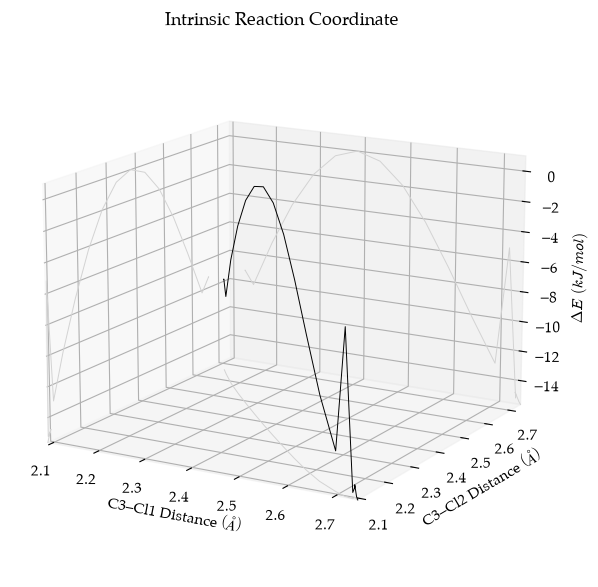

In [6]:
# The three things to plot: both C-Cl distances and the energy in water
x = data["C-Cl1"]
y = data["C-Cl2"]
z = data["E water (kJ/mol)"]

low = min(x.min(), y.min())
high = max(x.max(), y.max())

# A 3-D plot, seen from a little above
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(6,6))
ax.view_init(15, -60)

# Gray "shadows" of the path on the floor and two walls, then the path itself
ax.plot(x, y, zs=z.min(), zdir="z", color="lightgray", linewidth=0.7)
ax.plot(y, z, zs=low, zdir="x", color="lightgray", linewidth=0.7)
ax.plot(x, z, zs=high, zdir="y", color="lightgray", linewidth=0.7)
ax.plot(x, y, z, color="black", linewidth=0.7)

ax.set_xlabel(r"C3–Cl1 Distance $\left( \AA \right)$")
ax.set_ylabel(r"C3–Cl2 Distance $\left( \AA \right)$")
ax.set_zlabel(r"$\Delta E \  \left(kJ/mol\right)$")
ax.set_title("Intrinsic Reaction Coordinate")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_zlim(z.min(), max(z.max(), 1))

#fig.savefig("plot3.pdf")
plt.show()

| Line | Notes |
| :---- | :---- |
| `subplot_kw={"projection": "3d"}` | Asks `plt.subplots()` for a 3-D set of axes instead of a flat one. |
| `ax.view_init(15, -60)` | Looks at the box from 15&deg; above the floor, turned &minus;60&deg; around the vertical axis. Change these and see. |
| `ax.plot(x, y, zs=z.min(), zdir="z", ...)` | The **shadow on the floor**: the More O'Ferrall&ndash;Jencks plot, drawn flat at the lowest energy. |
| `ax.plot(y, z, zs=low, zdir="x", ...)` | The shadow on the wall at the lowest C3&ndash;Cl1 distance: energy vs. C3&ndash;Cl2. With `zdir="x"`, the two lists we give are drawn along the *y* and *z* axes. |
| `ax.plot(x, z, zs=high, zdir="y", ...)` | The shadow on the back wall: energy vs. C3&ndash;Cl1. |
| `ax.plot(x, y, z, ...)` | The path itself, in three dimensions. |

Does that help you to imagine the nucleophile translating in, the making and breaking of bonds, and the leaving group translating away? I wonder what other kinds of plots we could use.

## Summary

Even on the same structures, water changes the energy profile of the reaction a great deal. Near the transition state, energies in water along the gas phase path reproduce the *GAMESS* IRC in water almost exactly, about four times deeper than in gas phase. To see the chloride drift away into the water, we would need the path in water itself, which *GAMESS* could follow with its exact solvent gradients and *Psi4* (with the tools we have) could not. Should we **redo everything** that we did up until now with the solvent switched on? That will be left as an exercise for the reader.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the second "Solvent IRC Plots" notebook of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About half of the text is **my own work**, carried over word for word or lightly edited, including the introduction, the discussion of the energy profiles, the More O'Ferrall&ndash;Jencks plot and its "double ended hockey stick", and the 3-D plot. The **rest of the page** was written by an **LLM system** at my request. I asked it to load the JSON file written by the *Psi4* data notebook, to restyle the plots, and to compare the water energies along the *Psi4* gas phase path with my *GAMESS* IRC in water. The *Python* code, the line-by-line explanations of it and the commentary on the results were written by the LLM. The numbers quoted in the text come from my own calculations. Later, after the IRC in the [first notebook](ch5B-solvent.ipynb) was re-run, the LLM updated the numbers in the text to match the new path.
```